# Bassez et al. 2021 — Breast · Step 02: Cell-state manifold / trajectory
Fit the cell-state manifold and pseudotime. The scFates method is **matched to the topology** (03_eval fork 3):
`tree` only if a genuine Gast-vs-pSom bifurcation exists, otherwise `curve`. The root is derived from the
**signatures' developmental order** — Gast/pSom origin is the root, neural-crest/Crest is *late* — never the
Crest tip. The pseudotime curve is rendered **with edges** and checked for folds (03_eval fork 4); we do **not**
re-embed a linear compartment.

In [1]:
import os, sys, glob, io, contextlib
os.environ['R_HOME'] = '/home/caleb/miniconda3/envs/scFates/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

### Load processed manifold; recompute smoothed module scores for geography

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print('whole malignant manifold:', adata.shape[0], 'cells')
xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
u,s,vt = np.linalg.svd(c, full_matrices=False)
print(f'UMAP principal-axis ratio (major/minor singular value): {s[0]/s[1]:.2f}')
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,l in enumerate(['Gast','pSom','Crest']): adata.obs[l+'_sm'] = S[:,j]
print('raw module means (honest readout):', adata.obs[['Gast','pSom','Crest']].mean().round(4).to_dict())

whole malignant manifold: 65615 cells
UMAP principal-axis ratio (major/minor singular value): 1.29
raw module means (honest readout): {'Gast': -0.0136, 'pSom': 0.0221, 'Crest': -0.005}


### Module geography on the whole manifold (informs topology)
Smoothed correlations (graph-averaged scores *aid* the geography read; deliverable signature UMAPs in step 03
show the RAW scores). Gast and pSom co-vary and both oppose Crest — the signature of a single
(Gast/pSom)→Crest axis, not two competing arms.

In [4]:
print('spatial correlations on the whole manifold (smoothed):')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    r = np.corrcoef(adata.obs[a], adata.obs[b])[0,1]; print(f'  {a} vs {b}: r = {r:+.2f}')
print('raw-score correlations:')
for a,b in [('Gast','pSom'),('Crest','Gast'),('Crest','pSom')]:
    r = np.corrcoef(adata.obs[a], adata.obs[b])[0,1]; print(f'  {a} vs {b}: r = {r:+.2f}')
print('cycling fraction: %.3f (single low-cycling body)' % adata.obs['cycling'].mean())
sub = adata

spatial correlations on the whole manifold (smoothed):
  Gast_sm vs pSom_sm: r = -0.21
  Crest_sm vs Gast_sm: r = -0.24
  Crest_sm vs pSom_sm: r = -0.82
raw-score correlations:
  Gast vs pSom: r = -0.10
  Crest vs Gast: r = -0.36
  Crest vs pSom: r = -0.60
cycling fraction: 0.031 (single low-cycling body)


### Topology — tree vs curve
Two independent tests decide branching vs non-branching:
1. **PPT tree, does a Gast-enriched arm exist at any tip?** Fit the tree at several stiffnesses and read tip
   module identities. If *no* tip is Gast-enriched, the forks are density-lobe over-fitting of a single axis,
   not a Gast-vs-pSom bifurcation.
2. **Curve fold check.** Fit the principal curve and measure the fold self-approach ratio (min non-adjacent
   node distance / median edge length); >1 = fold-free.

In [5]:
def node_stats(a):
    B = np.asarray(a.uns['graph']['B']); R = np.asarray(a.obsm['X_R']); hard = R.argmax(1)
    df = pd.DataFrame({m:[a.obs[m+'_sm'][hard==k].mean() for k in range(B.shape[0])] for m in ['Gast','pSom','Crest']})
    deg = (B>0).sum(0); tip = np.where(deg==1)[0]; fork = np.where(deg>=3)[0]
    return df, tip, fork
print('PPT tree — is there a Gast-enriched arm at any tip?')
for Nn,lam in [(100,1000),(100,2000),(100,5000)]:
    a = sub.copy()
    with contextlib.redirect_stdout(io.StringIO()):
        scf.tl.tree(a, Nodes=Nn, use_rep='X_umap', method='ppt', ppt_lambda=lam, ppt_sigma=0.5, seed=SEED, plot=False)
    df, tip, fork = node_stats(a); tp = df.loc[tip].dropna()
    print(f'  N={Nn} lam={lam}: {len(tip)} tips, {len(fork)} forks | '
          f'max tip Gast={tp.Gast.max():+.3f}  max tip pSom={tp.pSom.max():+.3f}  max tip Crest={tp.Crest.max():+.3f}')
print('-> no Gast-enriched tip at any stiffness (max tip Gast <= 0): forks are lobe over-fitting of a single '
      '(Gast/pSom)->Crest axis, not a bifurcation.')

PPT tree — is there a Gast-enriched arm at any tip?
  N=100 lam=1000: 13 tips, 11 forks | max tip Gast=-0.001  max tip pSom=+0.052  max tip Crest=+0.011
  N=100 lam=2000: 12 tips, 10 forks | max tip Gast=-0.001  max tip pSom=+0.053  max tip Crest=+0.011
  N=100 lam=5000: 10 tips, 8 forks | max tip Gast=-0.001  max tip pSom=+0.047  max tip Crest=+0.010
-> no Gast-enriched tip at any stiffness (max tip Gast <= 0): forks are lobe over-fitting of a single (Gast/pSom)->Crest axis, not a bifurcation.


In [6]:
def fold_diag(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii,jj = np.where(np.triu(B>0)); med_edge = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a in range(F.shape[0]):
        for b in range(a+1, F.shape[0]):
            if G[a,b] >= 3: dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
    tips = int(((B>0).sum(0)==1).sum()); forks = int(((B>0).sum(0)>=3).sum())
    return dmin/med_edge, tips, forks
for Nn in [15, 20, 30]:
    a2 = sub.copy()
    with contextlib.redirect_stdout(io.StringIO()):
        scf.tl.curve(a2, Nodes=Nn, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
    sa, tips, forks = fold_diag(a2)
    print(f'curve N={Nn}: {tips} tips, {forks} forks | self-approach {sa:.2f}')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(sub, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa, tips, forks = fold_diag(sub)
print(f'chosen curve N=20: {tips} tips, {forks} forks | fold self-approach ratio = {sa:.2f} (>1 = fold-free)')
assert forks == 0 and sa > 1, 'topology check failed'
print('-> non-branching: scFates CURVE (not tree).')

curve N=15: 2 tips, 0 forks | self-approach 2.87
curve N=20: 2 tips, 0 forks | self-approach 2.59
curve N=30: 2 tips, 0 forks | self-approach 2.22
chosen curve N=20: 2 tips, 0 forks | fold self-approach ratio = 2.59 (>1 = fold-free)
-> non-branching: scFates CURVE (not tree).


### Root from the signatures' developmental order
For each curve tip, score the neighbourhood's Gast+pSom−Crest; root at the argmax (Gast/pSom-high, Crest-low
developmental origin). Crest is *late* and never the root.

In [7]:
B = np.asarray(sub.uns['graph']['B']); tps = np.where((B>0).sum(0)==1)[0]
R = np.asarray(sub.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info = {}
for tp in tps:
    m = np.isin(hard, np.where(D[tp]<=3)[0])
    info[tp] = (sub.obs['Gast_sm'][m].mean(), sub.obs['pSom_sm'][m].mean(), sub.obs['Crest_sm'][m].mean())
    print(f'tip {tp}: Gast={info[tp][0]:+.4f} pSom={info[tp][1]:+.4f} Crest={info[tp][2]:+.4f}')
root = int(max(tps, key=lambda tp: info[tp][0]+info[tp][1]-info[tp][2]))
print('derived root = tip', root, '(Gast/pSom-high, Crest-low developmental origin)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(sub, root); scf.tl.pseudotime(sub, n_map=1, seed=SEED)
t = sub.obs['t'].values
print('gradient along pseudotime (Spearman rho on smoothed):')
for smod in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,p = spearmanr(t, sub.obs[smod]); print(f'  {smod}: rho={rho:+.3f} p={p:.1e}')
tn = (t-t.min())/(t.max()-t.min())
for m,lab_ in [('Gast_sm','Gastrulation'),('pSom_sm','Somitogenesis'),('Crest_sm','Neural-crest')]:
    hi = sub.obs[m] >= sub.obs[m].quantile(0.9)
    print(f'{lab_}-high decile mean pseudotime = {tn[hi.values].mean():.2f}')
g2m = pd.to_numeric(sub.obs['g2m_score'], errors='coerce').fillna(0).values
g1s = pd.to_numeric(sub.obs['g1s_score'], errors='coerce').fillna(0).values
rho_c,_ = spearmanr(t, np.maximum(g1s, g2m))
print(f'caveat: pseudotime vs cycling score rho = {rho_c:+.2f} (secondary; axis is not proliferation-driven)')

tip 0: Gast=-0.0153 pSom=+0.0121 Crest=+0.0048
tip 2: Gast=-0.0150 pSom=+0.0239 Crest=-0.0045
derived root = tip 2 (Gast/pSom-high, Crest-low developmental origin)
gradient along pseudotime (Spearman rho on smoothed):
  Gast_sm: rho=-0.115 p=3.2e-193
  pSom_sm: rho=-0.273 p=0.0e+00
  Crest_sm: rho=+0.296 p=0.0e+00
Gastrulation-high decile mean pseudotime = 0.22
Somitogenesis-high decile mean pseudotime = 0.45
Neural-crest-high decile mean pseudotime = 0.39
caveat: pseudotime vs cycling score rho = +0.17 (secondary; axis is not proliferation-driven)


### Render the curve WITH EDGES (fold check on the actual embedding)

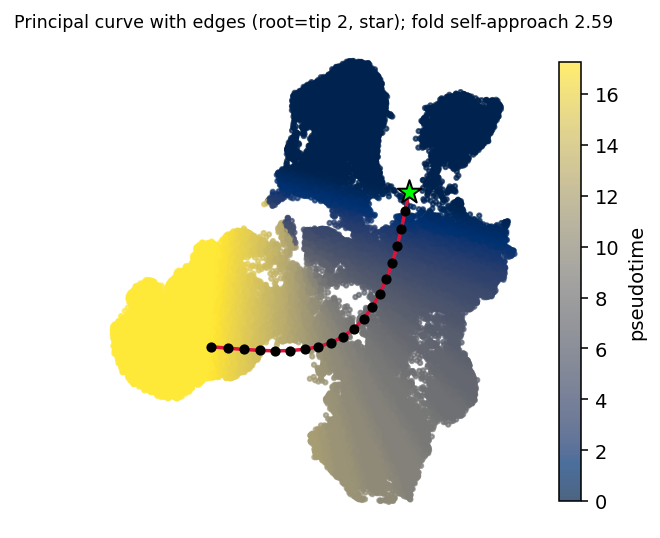

In [8]:
B = np.asarray(sub.uns['graph']['B']); F = sub.uns['graph']['F'].T
ii,jj = np.where(np.triu(B>0))
fig, ax = plt.subplots(figsize=(4.5,4.5))
sca = ax.scatter(sub.obsm['X_umap'][:,0], sub.obsm['X_umap'][:,1], c=sub.obs['t'], s=5, cmap='cividis', alpha=.7)
for a_,b_ in zip(ii,jj):
    ax.plot([F[a_,0],F[b_,0]],[F[a_,1],F[b_,1]], '-', color='crimson', lw=1.8, zorder=5)
ax.scatter(F[:,0],F[:,1], c='k', s=18, zorder=6)
ax.scatter(F[root,0],F[root,1], c='lime', s=160, marker='*', edgecolor='k', zorder=7)
ax.set_title(f'Principal curve with edges (root=tip {root}, star); fold self-approach {sa:.2f}', size=9)
ax.axis('off'); plt.colorbar(sca, ax=ax, fraction=0.045, label='pseudotime')
plt.show()

### Orient the house linear layout by pseudotime; save manifold.h5ad

In [9]:
t = sub.obs['t'].values
r = float(np.corrcoef(sub.obsm['X_umap_lin'][:,0], t)[0,1])
if r < 0:
    sub.obsm['X_umap_lin'][:,0] = -sub.obsm['X_umap_lin'][:,0]
    r = float(np.corrcoef(sub.obsm['X_umap_lin'][:,0], t)[0,1])
print(f'corr(x_lin, pseudotime) = {r:+.2f} (origin on left, terminus on right)')
assert r > 0.3, f'orientation not pseudotime-consistent (corr={r:.2f})'
sub.uns['epg'] = {'NodePositions': np.asarray(sub.uns['epg']['NodePositions'])}
sub.uns['graph'] = {'B': np.asarray(sub.uns['graph']['B']),
                    'F': np.asarray(sub.uns['graph']['F']),
                    'root': int(root), 'tips': np.asarray(tps)}
for k in list(sub.uns.keys()):
    if k not in ('epg','graph','pca','neighbors','umap','leiden','log1p'):
        pass
sub.write(os.path.join(pth_out, 'manifold.h5ad'))
print('saved manifold.h5ad')

corr(x_lin, pseudotime) = +0.94 (origin on left, terminus on right)
saved manifold.h5ad


### Deliverable — `manifold.pdf` (pseudotime, house linear layout)

saved manifold.pdf


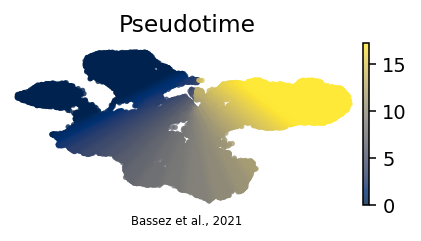

In [10]:
xl = sub.obsm['X_umap_lin']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
plot = sub.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=30, alpha=.8, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.text(.5,-.12,'Bassez et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight')
plt.show()
print('saved manifold.pdf')